# Project 3: Word Embeddings

**Albert Kabore**

PhD student in AI

## 1. Introduction

This project represents BBC news articles with term frequency–inverse document frequency (TF-IDF) and reduces their dimensionality using Principal Component Analysis (PCA). TF-IDF assigns weights to terms within each document. PCA combines these features into new coordinates ordered by the variance they retain.

The objective is to reduce the number of coordinates per document while preserving at least 90% of sample variance. The analysis explicitly calculates feature means, centered data, sample covariance, and sorted eigenvalues and eigenvectors. PCA maximizes retained variance for a fixed number of orthonormal projection directions (Jolliffe & Cadima, 2016). Here, information retention refers to variation in TF-IDF weights.

## 2. Dataset

The [BBC News Archive](https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive), distributed on Kaggle by `hgultekin`, contains 2,225 articles across five categories: business, entertainment, politics, sport, and tech. Each document combines an article's title and body. The category labels are not used to calculate TF-IDF weights or PCA directions.

## 3. Data Cleaning

The cleaning procedure checks the required columns, missing entries, and category labels before modifying the article text. The results recorded in `data/cleaning_report.json` are:

| Step | Operation | Result |
|---|---|---|
| Schema and missing entries | Check required columns, missing values, and expected categories | No missing entries or unknown categories |
| Whitespace | Strip ends and collapse repeated whitespace | 2,225 article bodies changed |
| Character repair | Replace one damaged currency character with £ based on context | One article changed |
| Exact duplicates | Keep the first occurrence of each normalized body | 136 copies removed |
| Near-duplicates | Compare bodies with identical headlines using Jaccard word-set similarity of at least 0.8 | 23 articles removed |
| Length | Remove bodies with fewer than 50 whitespace-separated words | None removed; shortest retained body has 84 words |

Jaccard similarity is the number of distinct words shared by two articles divided by the number in their union. The similarity and length thresholds are preprocessing choices. The same-headline rule can leave related stories with different titles. After cleaning, **2,066 articles** remain for TF-IDF and PCA.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("src").resolve()))

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from word_embeddings.cleaning import clean_dataset
from word_embeddings.data import load_raw
from word_embeddings.tfidf import TfidfVectorizer

np.set_printoptions(precision=6, suppress=True)
raw = load_raw()
articles, cleaning = clean_dataset(raw)
print("Raw articles:", len(raw))
print("Cleaned articles:", len(articles))
print("Exact / same-headline near-duplicates removed:",
      cleaning.exact_duplicates_removed, cleaning.near_duplicates_removed)

Matplotlib is building the font cache; this may take a moment.


Raw articles: 2225
Cleaned articles: 2066
Exact / same-headline near-duplicates removed: 136 23


## 4. TF-IDF Document Vectors

Term frequency `tf(t,d)` is the count of term t in document d. Document frequency `df(t)` counts documents containing t. With n documents, use:

`idf(t) = ln((1 + n) / (1 + df(t))) + 1`

Multiply TF by IDF, then divide each nonzero document vector by its Euclidean length (scikit-learn developers, *Feature extraction*).

The implementation lowercases text, retains tokens of at least two word characters, and removes English stop words. Tokens can contain letters, digits, and underscores. Keep the 1,000 most frequent terms among those appearing in at least two documents. Rows are documents; columns are terms.

The matrix is sparse in its values but stored as a dense NumPy array. The reduced vectors represent documents because each observation is an article.

In [2]:
vectorizer = TfidfVectorizer(max_features=1000, min_df=2)
X = vectorizer.fit_transform(articles["text"].tolist())
terms = vectorizer.get_feature_names_out()
n, p = X.shape
print("TF-IDF shape:", X.shape)
print(f"Zero entries: {(X == 0).mean():.2%}")
np.testing.assert_allclose(np.linalg.norm(X, axis=1), 1.0)

TF-IDF shape: (2066, 1000)
Zero entries: 93.28%


## 5. Principal Component Analysis

### 5.1 Feature Means

For feature j, `mean_j = (1/n) * sum_i X[i,j]`. Calculate the average TF-IDF weight of each term across documents.

In [3]:
mean = X.mean(axis=0)
print("Mean vector shape:", mean.shape)
display(pd.Series(mean, index=terms, name="mean TF-IDF")
        .sort_values(ascending=False).head(10))

Mean vector shape: (1000,)


said          0.069890
mr            0.043615
year          0.033988
new           0.028254
people        0.027744
film          0.025191
world         0.022958
time          0.021615
government    0.021416
game          0.021221
Name: mean TF-IDF, dtype: float64

### 5.2 Centering

Subtract each feature's mean: `X_centered = X - mean`. Each centered column then has mean zero within numerical precision. This places the origin at the average document. The columns are not scaled to unit variance.

In [4]:
X_centered = X - mean
print("Largest absolute centered-column mean:",
      np.abs(X_centered.mean(axis=0)).max())
np.testing.assert_allclose(X_centered.mean(axis=0), 0, atol=1e-12)

Largest absolute centered-column mean: 3.809993489894889e-16


### 5.3 Sample Covariance

`C = X_centered.T @ X_centered / (n - 1)`

The diagonal entries are feature variances. Off-diagonal entries measure how two term weights vary together around their means. The denominator n - 1 accounts for estimating the mean from these observations.

The matrix is symmetric and positive semidefinite, so its eigenvalues are real and nonnegative in exact arithmetic.

In [5]:
covariance = X_centered.T @ X_centered / (n - 1)
print("Covariance shape:", covariance.shape)
np.testing.assert_allclose(covariance, covariance.T, atol=1e-12)
np.testing.assert_allclose(covariance, np.cov(X, rowvar=False), atol=1e-12)
selected = ["said", "mr", "labour", "blair", "film", "game"]
selected_idx = [vectorizer.vocabulary_[word] for word in selected]
display(pd.DataFrame(covariance[np.ix_(selected_idx, selected_idx)],
                     index=selected, columns=selected).round(6))

Covariance shape: (1000, 1000)


,said,mr,labour,blair,film,game
said,0.002981,0.000975,0.000275,0.000301,-0.000477,-0.000255
mr,0.000975,0.006949,0.001890,0.002213,-0.000581,-0.000645
labour,0.000275,0.001890,0.004176,0.001595,-0.000402,-0.000352
blair,0.000301,0.002213,0.001595,0.003604,-0.000309,-0.000276
film,-0.000477,-0.000581,-0.000402,-0.000309,0.008568,-0.000329
game,-0.000255,-0.000645,-0.000352,-0.000276,-0.000329,0.004264


### 5.4 Sorted Eigenvalues and Eigenvectors

Solve `C @ v_i = lambda_i * v_i`. Each unit-length eigenvector is a direction through the centered data. Its eigenvalue is the variance along that direction.

NumPy's `eigh` returns ascending eigenvalues and corresponding eigenvectors in columns. Reorder both arrays with the same indices to keep the eigenpairs matched (NumPy Developers, *numpy.linalg.eigh*).

An eigenvector's sign is arbitrary. Set its largest-magnitude entry positive for consistent display. Repeated eigenvalues may permit different orthonormal bases for the same subspace.

In [6]:
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = np.maximum(eigenvalues[order], 0.0)
eigenvectors = eigenvectors[:, order]

pivots = np.argmax(np.abs(eigenvectors), axis=0)
signs = np.sign(eigenvectors[pivots, np.arange(p)])
eigenvectors *= np.where(signs == 0, 1, signs)

np.testing.assert_allclose(covariance @ eigenvectors,
                           eigenvectors * eigenvalues, atol=1e-12)
np.testing.assert_allclose(eigenvectors.T @ eigenvectors, np.eye(p), atol=1e-12)
assert np.all(np.diff(eigenvalues) <= 0)
np.testing.assert_allclose(eigenvalues.sum(), np.trace(covariance))

ratios = eigenvalues / eigenvalues.sum()
display(pd.DataFrame({"eigenvalue": eigenvalues[:10],
                      "% variance": 100 * ratios[:10]},
                     index=[f"PC{i}" for i in range(1, 11)]).round(6))
print("Selected entries from the sorted eigenvector columns:")
display(pd.DataFrame(eigenvectors[selected_idx, :3], index=selected,
                     columns=["PC1", "PC2", "PC3"]).round(6))
print("Total sample variance:", eigenvalues.sum())

,eigenvalue,% variance
PC1,0.022090,2.342885
PC2,0.017540,1.860326
PC3,0.016323,1.731248
PC4,0.013055,1.384670
PC5,0.009655,1.024017
PC6,0.008573,0.909275
PC7,0.008384,0.889226
PC8,0.007910,0.838919
PC9,0.007508,0.796349
PC10,0.006855,0.727086


Selected entries from the sorted eigenvector columns:


,PC1,PC2,PC3
said,0.121288,0.002514,-0.029479
mr,0.357007,0.167236,0.085800
labour,0.240837,0.202448,0.084445
blair,0.193686,0.169348,0.072873
film,-0.142227,-0.124481,0.541733
game,-0.155861,0.137226,-0.088092


Total sample variance: 0.942843961913586


### 5.5 Projection and Retained Variance

The variance along a unit-length direction v is `v.T @ C @ v`. The leading eigenvectors maximize the total variance of k orthonormal projection directions (Jolliffe & Cadima, 2016).

Each component retains `eigenvalue[i] / sum(eigenvalues)` of total variance. Choose the smallest k whose cumulative fraction reaches 90%. With the first k eigenvectors as columns of W, compute `Z = X_centered @ W`. Each document then has k coordinates.

Reconstruct the weights with `X_hat = Z @ W.T + mean`. The residual squared error is `(n - 1) * sum(eigenvalues[k:])`. Dividing it by `sum((X - mean)**2)` gives relative squared error, equal to one minus the retained variance fraction. This links variance maximization directly to minimum reconstruction error.

In [7]:
cumulative = np.cumsum(ratios)
variance_target = 0.90
k = int(np.searchsorted(cumulative, variance_target) + 1)
W = eigenvectors[:, :k]
Z = X_centered @ W

print("Reduced shape:", Z.shape)
print(f"Variance retained: {cumulative[k - 1]:.6%}")
print(f"Reduction in coordinates per document: {1 - k / p:.1%}")
assert cumulative[k - 1] >= variance_target
assert k == 1 or cumulative[k - 2] < variance_target
np.testing.assert_allclose(Z.var(axis=0, ddof=1), eigenvalues[:k], atol=1e-12)
display(pd.DataFrame({
    "variance target": ["50%", "80%", "90%"],
    "components": [int(np.searchsorted(cumulative, t) + 1) for t in (0.5, 0.8, 0.9)],
}))

Reduced shape: (2066, 553)
Variance retained: 90.016090%
Reduction in coordinates per document: 44.7%


,variance target,components
0,50%,132
1,80%,386
2,90%,553


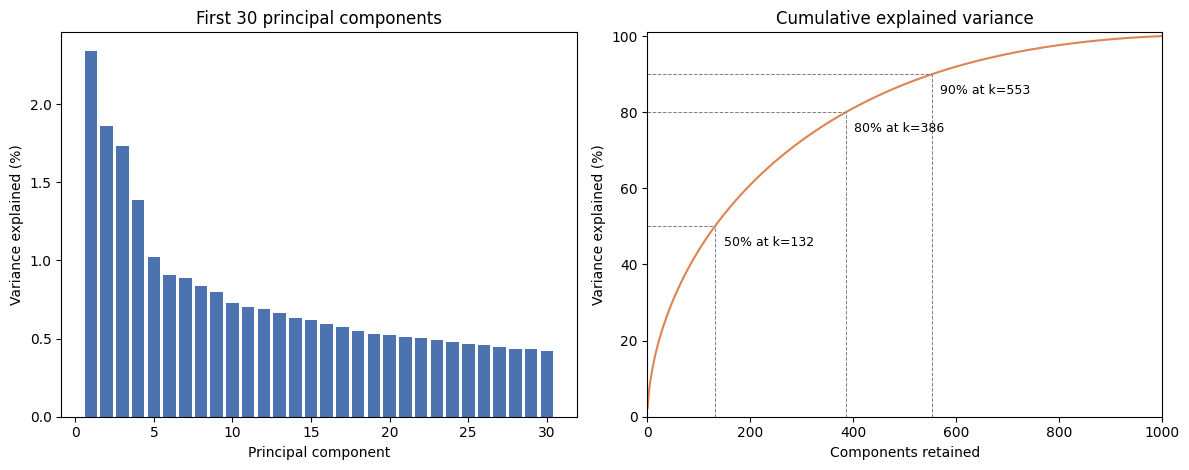

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.bar(np.arange(1, 31), ratios[:30] * 100, color="#4c72b0")
ax1.set(title="First 30 principal components", xlabel="Principal component",
        ylabel="Variance explained (%)")
ax2.plot(np.arange(1, p + 1), cumulative * 100, color="#dd8452")
ax2.set(title="Cumulative explained variance", xlabel="Components retained",
        ylabel="Variance explained (%)", ylim=(0, 101), xlim=(0, p))
for target in (0.5, 0.8, 0.9):
    count = int(np.searchsorted(cumulative, target) + 1)
    ax2.plot([count, count], [0, target * 100], color="grey", lw=0.7, ls="--")
    ax2.plot([0, count], [target * 100, target * 100], color="grey", lw=0.7, ls="--")
    ax2.annotate(f"{target:.0%} at k={count}", (count, target * 100),
                 textcoords="offset points", xytext=(6, -14), fontsize=9)
fig.tight_layout()
Path("results").mkdir(exist_ok=True)
fig.savefig("results/scree_plot.png", dpi=150)
plt.show()

## 6. Results and Verification

The 90% target retains 553 components, giving a 2,066-by-553 matrix and approximately 90.02% retained variance. This reduces the number of coordinates per document by 44.7%. Two components retain only 4.20%.

The checks above verify centering, covariance, sorting, orthonormality, the eigenpair equation, and projected variance. The following cell compares the explicit calculations with the project package and the first ten components from scikit-learn PCA.

In [9]:
from sklearn.decomposition import PCA as SklearnPCA
from word_embeddings.pca import PCA

reference = SklearnPCA(n_components=10, svd_solver="full").fit(X)
package_pca = PCA(n_components=k).fit(X)
np.testing.assert_allclose(package_pca.mean_, mean)
np.testing.assert_allclose(package_pca.covariance_, covariance, atol=1e-12)
np.testing.assert_allclose(package_pca.eigenvalues_, eigenvalues, atol=1e-12)
np.testing.assert_allclose(package_pca.transform(X), Z, atol=1e-10)
np.testing.assert_allclose(eigenvalues[:10], reference.explained_variance_, atol=1e-12)
cosines = np.abs(np.sum(eigenvectors[:, :10].T * reference.components_, axis=1))
np.testing.assert_allclose(cosines, np.ones(10), atol=1e-9)

print("Maximum covariance difference from NumPy:",
      np.abs(covariance - np.cov(X, rowvar=False)).max())
print("Maximum leading-eigenvalue difference from scikit-learn:",
      np.abs(eigenvalues[:10] - reference.explained_variance_).max())
print("All numerical checks passed.")

Maximum covariance difference from NumPy: 4.336808689942018e-19
Maximum leading-eigenvalue difference from scikit-learn: 1.3877787807814457e-17
All numerical checks passed.


### 6.1 Reconstruction and Projection Comparison

The following calculations measure what the reduction discards. MSE is averaged over all original matrix entries; relative squared error uses mean-only reconstruction as its baseline. The 552/553 comparison checks that the 90% threshold is reached with the smallest number of components. A single random orthonormal basis of the same dimension provides a comparison for the directions selected by PCA.

In [10]:
import json
import platform
import sklearn

baseline_mse = float(np.mean(X_centered ** 2))
reconstruction = []
for count in (2, 50, 132, 386, 552, 553, 1000):
    directions = eigenvectors[:, :count]
    coordinates = X_centered @ directions
    residual = X_centered - coordinates @ directions.T
    mse = float(np.mean(residual ** 2))
    expected_mse = float((n - 1) * eigenvalues[count:].sum() / (n * p))
    np.testing.assert_allclose(mse, expected_mse, atol=1e-15)
    reconstruction.append({
        "k": count, "variance_fraction": float(cumulative[count - 1]),
        "mse_per_entry": mse, "relative_squared_error": mse / baseline_mse,
    })
q, _ = np.linalg.qr(np.random.default_rng(42).normal(size=(p, k)))
random_retained = float(np.sum(q * (covariance @ q)) / eigenvalues.sum())
assert cumulative[k - 1] >= random_retained
print("Mean-only reconstruction MSE:", baseline_mse)
display(pd.DataFrame(reconstruction))
print(f"One random orthonormal basis, k={k}: {random_retained:.4%} variance")
print(f"PCA basis, k={k}: {cumulative[k - 1]:.4%} variance")
print("Mean and variance for selected terms:")
display(pd.DataFrame({"mean": mean[selected_idx],
                      "variance": np.diag(covariance)[selected_idx]},
                     index=selected).round(6))

analysis = {
    "n_documents": n, "n_terms": p, "sparsity": float((X == 0).mean()),
    "average_nonzero_terms_per_document": float(np.count_nonzero(X) / n),
    "mean_weights": {w: float(mean[j]) for w, j in zip(selected, selected_idx)},
    "max_centered_column_mean": float(np.abs(X_centered.mean(axis=0)).max()),
    "covariance_terms": selected,
    "covariance_values": covariance[np.ix_(selected_idx, selected_idx)].tolist(),
    "top10_eigenvalues": eigenvalues[:10].tolist(),
    "selected_eigenvector_coefficients": {
        w: eigenvectors[j, :3].tolist() for w, j in zip(selected, selected_idx)},
    "total_variance": float(eigenvalues.sum()),
    "top4_variance_fraction": float(cumulative[3]),
    "reconstruction": reconstruction, "mean_only_reconstruction_mse": baseline_mse,
    "random_projection": {"seed": 42, "k": k, "variance_fraction": random_retained},
    "max_eigenpair_residual": float(np.abs(
        covariance @ eigenvectors - eigenvectors * eigenvalues).max()),
    "max_orthogonality_error": float(np.abs(eigenvectors.T @ eigenvectors - np.eye(p)).max()),
    "minimum_eigenvalue": float(eigenvalues[-1]),
    "environment": {"python": platform.python_version(), "numpy": np.__version__,
                    "scikit_learn": sklearn.__version__},
}
Path("results/output_analysis.json").write_text(
    json.dumps(analysis, indent=2), encoding="utf-8")
print("Saved results/output_analysis.json")

Mean-only reconstruction MSE: 0.0009423875998797459


,k,variance_fraction,mse_per_entry,relative_squared_error
0,2,0.042032,9.027771e-04,9.579679e-01
1,50,0.305482,6.545049e-04,6.945177e-01
2,132,0.501415,4.698605e-04,4.985852e-01
3,386,0.800519,1.879886e-04,1.994812e-01
4,552,0.899704,9.451818e-05,1.002965e-01
5,553,0.900161,9.408713e-05,9.983910e-02
6,1000,1.000000,5.219235e-33,5.538311e-30


One random orthonormal basis, k=553: 55.3384% variance
PCA basis, k=553: 90.0161% variance
Mean and variance for selected terms:


,mean,variance
said,0.069890,0.002981
mr,0.043615,0.006949
labour,0.017413,0.004176
blair,0.014131,0.003604
film,0.025191,0.008568
game,0.021221,0.004264


Saved results/output_analysis.json


The largest mean among the selected terms belongs to said, but film has higher variance. The covariance signs match the contrasts in the eigenvectors: labour and blair covary positively, while labour and film covary negatively. Film's large PC3 coefficient and game's changing relationship to labour across components indicate mixed lexical contrasts.

The first four components retain only 7.32% of total variance. At 553 dimensions, relative reconstruction error is 9.98%; at two dimensions it is 95.80%. The 552-component representation misses the 90% target. The comparison with a random basis illustrates why direction selection matters, while the variance-maximization argument establishes optimality for a fixed number of orthonormal directions.

## 7. Observations

- Mean weights differed: said averaged 0.069890 and mr 0.043615; centering reduced every feature mean to numerical zero within rounding precision.

- Labour and blair had positive covariance, 0.001595, while labour and film had negative covariance, -0.000402, revealing contrasting document weight patterns.

- PC1 combined positive political vocabulary with negative film and game coefficients; PC3 gave film a much stronger positive coefficient, 0.541733.

- The first four components retained only 7.32% of variance; reaching 80% required 386 dimensions, and reaching 90% required 553 dimensions.

- Reconstruction error at 553 components was 0.000094087 per entry, equivalent to 9.98% of the mean-only reconstruction error across all documents.

## 8. Final Insights

- The measured spectrum supports moderate compression at the selected threshold: 553 components retain 90.02%, whereas 386 retain 80.05%. Recovering approximately ten additional percentage points therefore costs 167 coordinates. Since the first four components retain only 7.32%, interpretable leading directions account for a small share of the full representation's measured variation.

- Positive labour-blair covariance and negative labour-film covariance agree with PC1's opposing political and entertainment coefficients. Film dominates PC3; game opposes labour in PC1 but aligns with it in PC2. These relative patterns show several overlapping vocabulary contrasts, so assigning each principal component a distinct topic would misrepresent the calculated structure.

- At 553 dimensions, reconstruction leaves 9.98% of centered squared variation, compared with 95.80% at two dimensions. One fixed-seed orthogonal projection retains only 55.34% at 553 dimensions, supporting the value of selecting eigenvectors. This comparison illustrates PCA's advantage; the variance-maximization argument establishes optimality, while neither result establishes preservation of semantic meaning.

## 9. Recommendations

- Use 553 components for the chosen 90% target: 552 retain only 89.97%, so rounding the cumulative percentages could select an insufficient dimension. Consider 386 components only when accepting approximately 20% reconstruction loss is appropriate. Report the threshold, dimension, retained fraction, and relative reconstruction error together to make the compromise explicit.

- Investigate preprocessing through controlled comparisons focused on the observed loadings. Removing mr merely because it resembles a style term could remove political distinctions represented by PC1. Compare versions with and without selected terms, refitting TF-IDF and PCA each time, and examine changes in loadings, covariance, and reconstruction at matched dimensions.

- Evaluate reconstruction relative to the mean-only baseline, since the small absolute error partly reflects normalized, mostly zero TF-IDF weights. Distinguish coordinate reduction from storage savings: original documents average about 67 nonzero weights, whereas the reduced vectors contain 553 dense coordinates. Measure sparse and dense storage before making any efficiency claim.

## 10. Conclusion

PCA reduces the 1,000-feature representation of 2,066 cleaned articles to 553 coordinates, retaining 90.0161% of sample variance. This is the smallest dimension meeting the selected 90% target. Reconstruction leaves 9.9839% of the centered squared variation, so the reduction has a measurable cost even though its absolute MSE is small.

The covariance and loadings identify overlapping lexical contrasts: political terms covary positively and oppose film weights on PC1, while film has its largest displayed coefficient on PC3. These interpretable directions retain only part of the corpus's variation. The explicit mean, centering, covariance, sorted eigenpairs, and reconstruction checks establish the required computations and clarify their limits: retained variance measures variation in TF-IDF weights, not preserved meaning or task accuracy.

## 11. References

- hgultekin. (n.d.). [BBC News Archive](https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive) [Data set]. Kaggle.
- Jolliffe, I. T., & Cadima, J. (2016). [Principal component analysis: A review and recent developments](https://doi.org/10.1098/rsta.2015.0202). *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202.
- NumPy Developers. (n.d.). [numpy.linalg.eigh](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html).
- scikit-learn developers. (n.d.). [Feature extraction: TF-IDF term weighting](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).
- scikit-learn developers. (n.d.). [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).


## 12. AI Use and Disclosure

I used OpenAI Codex to assist with code development, interpretation of results, and drafting and revising the notebook and report. The work was verified by executing the notebook, running automated tests, comparing numerical results with NumPy and scikit-learn, and checking cited sources; I remain responsible for the accuracy, originality, and integrity of this submission.